<a href="https://colab.research.google.com/github/khalilinsights/ONE-TIME-SALES-AND-MARKETING-LTD./blob/main/ONE_TIME_SALES_AND_MARKETING_LTD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

PALETTE = ['#2E75B6', '#ED7D31', '#A9D18E']

In [ ]:
df = pd.read_csv('/content/Sales Data_PDA_4052 csv.csv', encoding='latin-1')
print(df.shape)
df.head()

(1001, 7)


,order_id,customer_id,sales_person,priority,ship_mode,date,value_£
0,8999,C406,Kelly,High,Plane,12/06/2020,"£1,553.44"
1,47872,C100,Kelly,Critical,Plane,12/06/2020,£315.40
2,29988,C006,Kelly,High,Lorry,12/06/2020,"£5,075.89"
3,37348,C492,Kelly,High,Plane,13/06/2020,£520.67
4,28001,C231,Kelly,Critical,Plane,14/06/2020,"£8,431.37"


In [ ]:
df.info()
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001 entries, 0 to 1000
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   order_id      1001 non-null   int64 
 1   customer_id   1001 non-null   object
 2   sales_person  1001 non-null   object
 3   priority      1001 non-null   object
 4   ship_mode     1001 non-null   object
 5   date          1001 non-null   object
 6   value_£       1001 non-null   object
dtypes: int64(1), object(6)
memory usage: 54.9+ KB
order_id        0
customer_id     0
sales_person    0
priority        0
ship_mode       0
date            0
value_£         0
dtype: int64
Duplicates: 0


In [ ]:
df['value_£'] = (df['value_£']
                 .str.replace('£', '', regex=False)
                 .str.replace(',', '', regex=False))
df['value_£'] = pd.to_numeric(df['value_£'], errors='coerce')

df['date'] = pd.to_datetime(df['date'], dayfirst=True)

df['sales_person'] = df['sales_person'].astype('category')
df['priority']     = df['priority'].astype('category')
df['ship_mode']    = df['ship_mode'].astype('category')

In [ ]:
print(df.dtypes)
print(df.isnull().sum())

order_id                 int64
customer_id             object
sales_person          category
priority              category
ship_mode             category
date            datetime64[ns]
value_£                float64
dtype: object
order_id        0
customer_id     0
sales_person    0
priority        0
ship_mode       0
date            0
value_£         0
dtype: int64


In [ ]:
print(df['value_£'].describe())
print(f"Skewness: {df['value_£'].skew():.2f}")
print(f"Kurtosis: {df['value_£'].kurt():.2f}")

count     1001.000000
mean      1778.402248
std       3457.457206
min          2.450000
25%        134.400000
50%        417.580000
75%       1816.930000
max      27448.240000
Name: value_£, dtype: float64
Skewness: 3.77
Kurtosis: 17.42


In [ ]:
print(df.groupby('sales_person', observed=True)['value_£']
        .agg(count='count', total='sum', mean='mean',
             median='median', std='std').round(2))

              count      total     mean  median      std
sales_person                                            
Kelly           319  558659.62  1751.28  366.84  3231.78
Peter           344  549292.06  1596.78  338.20  3391.70
Pryia           338  672228.97  1988.84  520.02  3718.74


In [ ]:
print(df['priority'].value_counts())
print(df['ship_mode'].value_counts())

priority
Critical         221
Not Specified    213
Low              200
High             196
Medium           171
Name: count, dtype: int64
ship_mode
Plane    770
Lorry    126
Van      105
Name: count, dtype: int64


In [ ]:
df['month']      = df['date'].dt.month
df['month_name'] = df['date'].dt.strftime('%b')
df['month_year'] = df['date'].dt.to_period('M')

priority_map = {'Low': 0, 'Medium': 1, 'High': 2, 'Critical': 3}
df['priority_num'] = df['priority'].map(priority_map).astype(float)

In [ ]:
Q1  = df['value_£'].quantile(0.25)
Q3  = df['value_£'].quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR
df['is_outlier'] = df['value_£'] > upper_fence

print(f"Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
print(f"Lower fence = {lower_fence:.2f}, Upper fence = {upper_fence:.2f}")
print(f"Outliers: {df['is_outlier'].sum()} ({100 * df['is_outlier'].mean():.1f}%)")
print(df.shape)

Q1 = 134.40, Q3 = 1816.93, IQR = 1682.53
Lower fence = -2389.39, Upper fence = 4340.73
Outliers: 122 (12.2%)
(1001, 12)


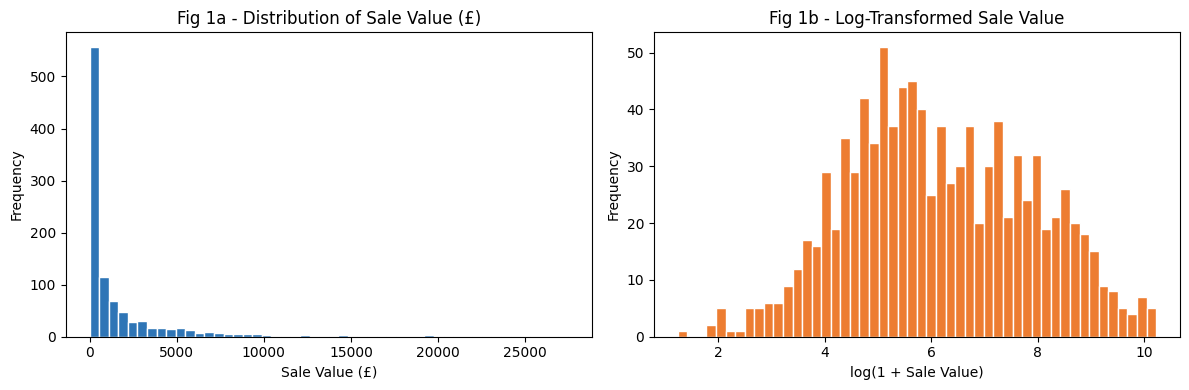

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['value_£'], bins=50, color='#2E75B6', edgecolor='white')
axes[0].set_title('Fig 1a - Distribution of Sale Value (£)')
axes[0].set_xlabel('Sale Value (£)')
axes[0].set_ylabel('Frequency')
axes[1].hist(np.log1p(df['value_£']), bins=50, color='#ED7D31', edgecolor='white')
axes[1].set_title('Fig 1b - Log-Transformed Sale Value')
axes[1].set_xlabel('log(1 + Sale Value)')
axes[1].set_ylabel('Frequency')
plt.tight_layout()
plt.savefig('fig1_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

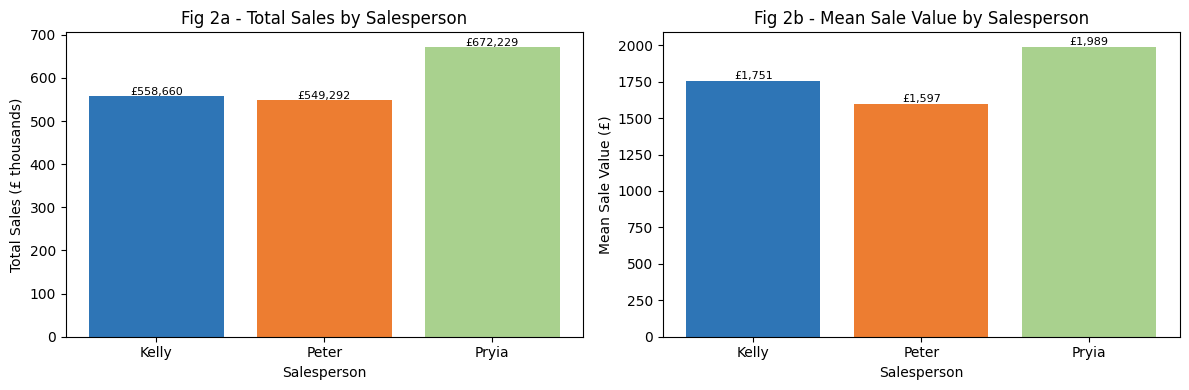

In [ ]:
sp = (df.groupby('sales_person', observed=True)['value_£']
        .agg(total='sum', mean='mean').reset_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bars = axes[0].bar(sp['sales_person'], sp['total'] / 1000, color=PALETTE)
for b, v in zip(bars, sp['total']):
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 3,
                 f'£{v:,.0f}', ha='center', fontsize=8)
axes[0].set_title('Fig 2a - Total Sales by Salesperson')
axes[0].set_xlabel('Salesperson')
axes[0].set_ylabel('Total Sales (£ thousands)')

bars = axes[1].bar(sp['sales_person'], sp['mean'], color=PALETTE)
for b, v in zip(bars, sp['mean']):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 15,
                 f'£{v:,.0f}', ha='center', fontsize=8)
axes[1].set_title('Fig 2b - Mean Sale Value by Salesperson')
axes[1].set_xlabel('Salesperson')
axes[1].set_ylabel('Mean Sale Value (£)')
plt.tight_layout()
plt.savefig('fig2_salesperson.png', dpi=200, bbox_inches='tight')
plt.show()

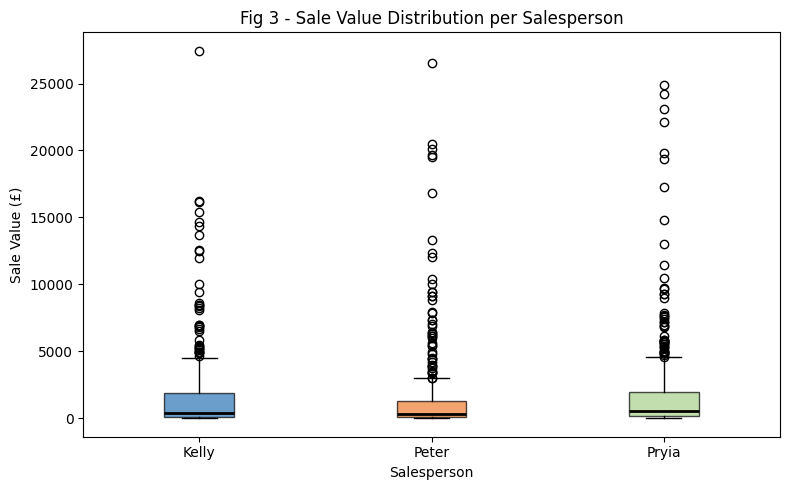

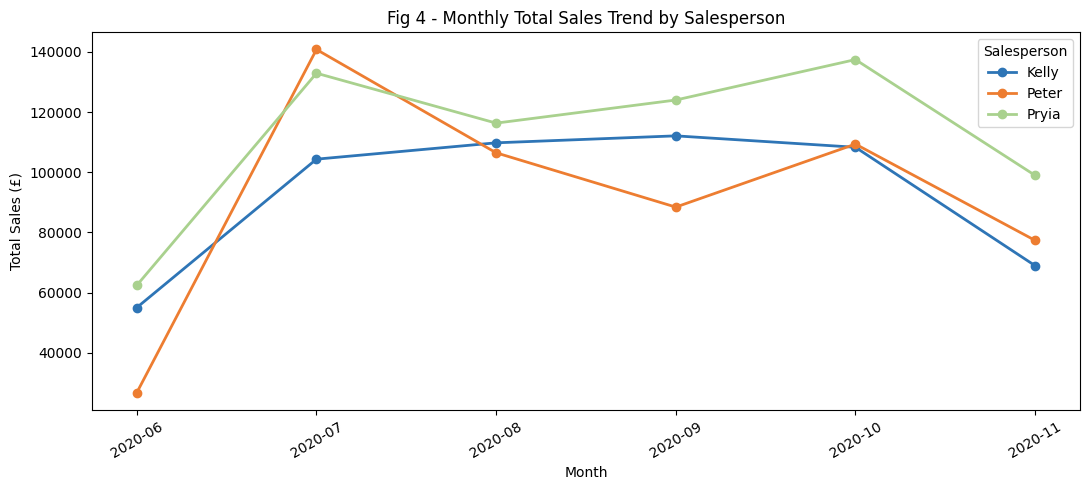

In [ ]:
# Fig 3
fig, ax = plt.subplots(figsize=(8, 5))
data_by_sp = [df[df['sales_person'] == s]['value_£'].values
              for s in ['Kelly', 'Peter', 'Pryia']]
bp = ax.boxplot(data_by_sp, labels=['Kelly', 'Peter', 'Pryia'],
                patch_artist=True, medianprops=dict(color='black', linewidth=2))
for patch, c in zip(bp['boxes'], PALETTE):
    patch.set_facecolor(c)
    patch.set_alpha(0.7)
ax.set_title('Fig 3 - Sale Value Distribution per Salesperson')
ax.set_xlabel('Salesperson')
ax.set_ylabel('Sale Value (£)')
plt.tight_layout()
plt.savefig('fig3_boxplot.png', dpi=200, bbox_inches='tight')
plt.show()

# Fig 4
monthly = (df.groupby(['month_year', 'sales_person'], observed=True)['value_£']
             .sum().reset_index())
monthly['month_year'] = monthly['month_year'].astype(str)

fig, ax = plt.subplots(figsize=(11, 5))
for s, c in zip(['Kelly', 'Peter', 'Pryia'], PALETTE):
    sub = monthly[monthly['sales_person'] == s]
    ax.plot(sub['month_year'], sub['value_£'], marker='o',
            label=s, color=c, linewidth=2)
ax.set_title('Fig 4 - Monthly Total Sales Trend by Salesperson')
ax.set_xlabel('Month')
ax.set_ylabel('Total Sales (£)')
ax.legend(title='Salesperson')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('fig4_trend.png', dpi=200, bbox_inches='tight')
plt.show()

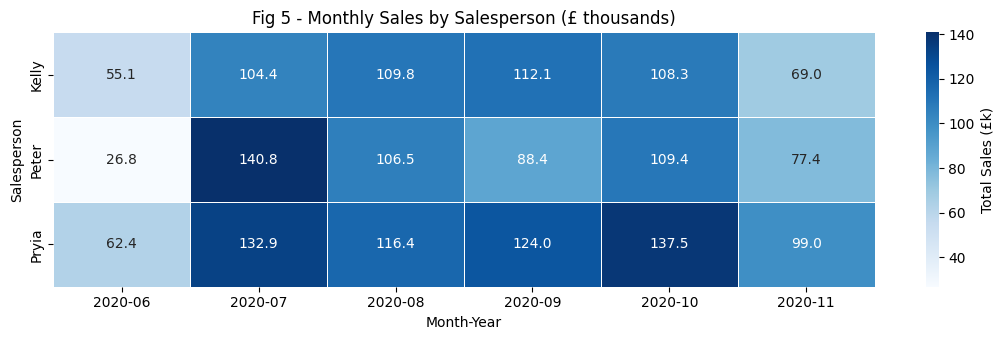

In [ ]:
pivot = df.pivot_table(values='value_£', index='sales_person',
                       columns='month_year', aggfunc='sum', observed=True)
pivot.columns = [str(c) for c in pivot.columns]

fig, ax = plt.subplots(figsize=(11, 3.5))
sns.heatmap(pivot / 1000, annot=True, fmt='.1f', cmap='Blues',
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Total Sales (£k)'})
ax.set_title('Fig 5 - Monthly Sales by Salesperson (£ thousands)')
ax.set_xlabel('Month-Year')
ax.set_ylabel('Salesperson')
plt.tight_layout()
plt.savefig('fig5_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

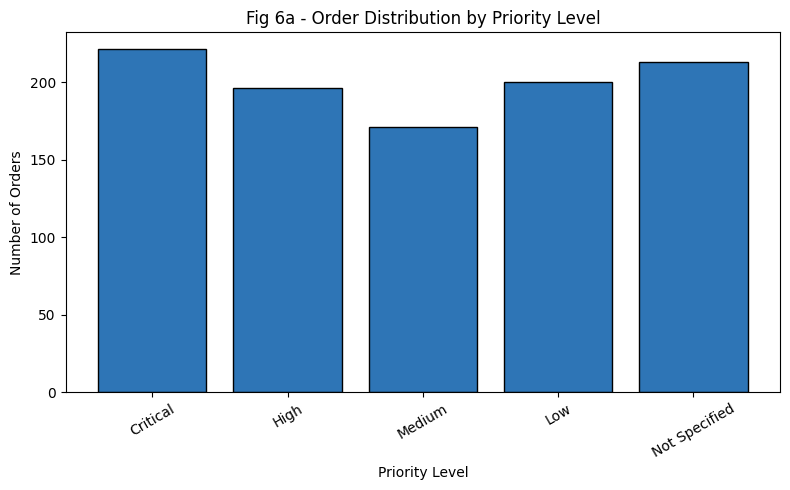

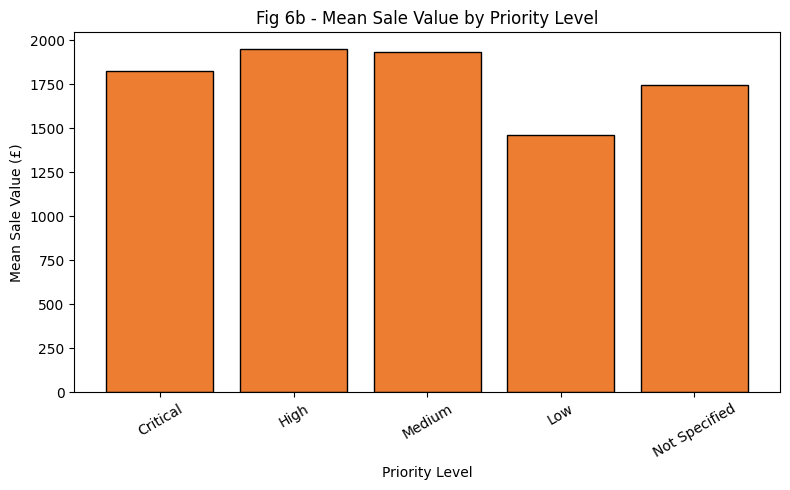

In [ ]:
priority_order = ['Critical', 'High', 'Medium', 'Low', 'Not Specified']

# Fig 6a
counts = df['priority'].value_counts().reindex(priority_order)
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(counts.index, counts.values, color='#2E75B6', edgecolor='black')
ax.set_title('Fig 6a - Order Distribution by Priority Level')
ax.set_xlabel('Priority Level')
ax.set_ylabel('Number of Orders')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('fig6a_priority_count.png', dpi=200, bbox_inches='tight')
plt.show()

# Fig 6b
means = (df.groupby('priority', observed=True)['value_£']
           .mean().reindex(priority_order))
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(means.index, means.values, color='#ED7D31', edgecolor='black')
ax.set_title('Fig 6b - Mean Sale Value by Priority Level')
ax.set_xlabel('Priority Level')
ax.set_ylabel('Mean Sale Value (£)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('fig6b_priority_mean.png', dpi=200, bbox_inches='tight')
plt.show()

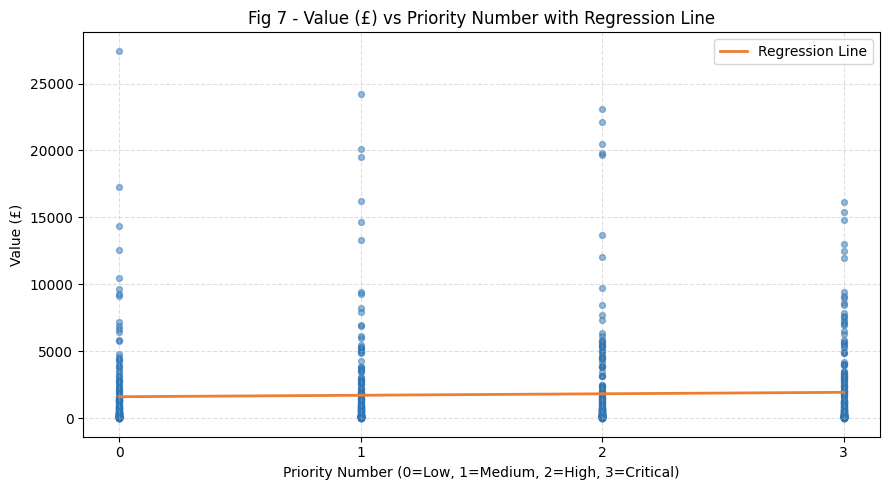

In [ ]:
df_corr = df[df['priority_num'].notna()].copy()
slope, intercept, r, p, se = stats.linregress(df_corr['priority_num'],
                                              df_corr['value_£'])
x_line = np.array([0, 3])

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df_corr['priority_num'], df_corr['value_£'],
           alpha=0.5, s=18, color='#2E75B6')
ax.plot(x_line, intercept + slope * x_line, color='#ED7D31',
        linewidth=2, label='Regression Line')
ax.set_xticks([0, 1, 2, 3])
ax.set_title('Fig 7 - Value (£) vs Priority Number with Regression Line')
ax.set_xlabel('Priority Number (0=Low, 1=Medium, 2=High, 3=Critical)')
ax.set_ylabel('Value (£)')
ax.legend()
ax.grid(linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('fig7_scatter.png', dpi=200, bbox_inches='tight')
plt.show()

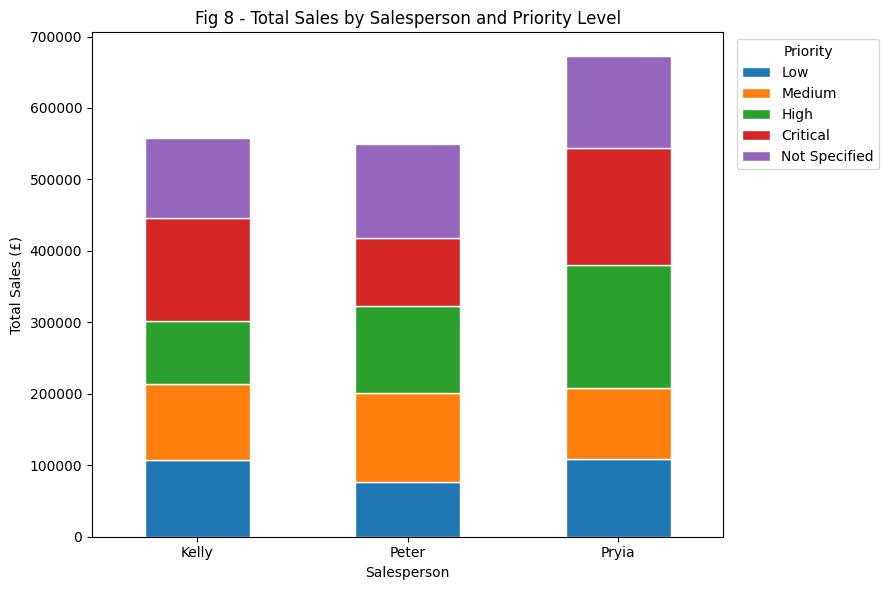

In [ ]:
sp_pri = (df.groupby(['sales_person', 'priority'], observed=True)['value_£']
            .sum().unstack()[['Low', 'Medium', 'High', 'Critical', 'Not Specified']])

fig, ax = plt.subplots(figsize=(9, 6))
sp_pri.plot(kind='bar', stacked=True, ax=ax, edgecolor='white')
ax.set_title('Fig 8 - Total Sales by Salesperson and Priority Level')
ax.set_xlabel('Salesperson')
ax.set_ylabel('Total Sales (£)')
ax.legend(title='Priority', bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('fig8_stacked.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
sample = df['value_£'].dropna().sample(500, random_state=42)
stat, p = stats.shapiro(sample)
print(f'W = {stat:.4f}, p = {p:.6f}')

W = 0.4971, p = 0.000000


In [ ]:
df_corr = df[df['priority_num'].notna()].copy()

corr_s, p_s = stats.spearmanr(df_corr['priority_num'], df_corr['value_£'])
corr_p, p_p = stats.pearsonr(df_corr['priority_num'], df_corr['value_£'])

print(f'Spearman: r = {corr_s:.4f}, p = {p_s:.4f}')
print(f'Pearson:  r = {corr_p:.4f}, p = {p_p:.4f}')

Spearman: r = 0.0634, p = 0.0753
Pearson:  r = 0.0371, p = 0.2980


In [ ]:
groups = [df[df['sales_person'] == s]['value_£'].values
          for s in ['Kelly', 'Peter', 'Pryia']]
h_stat, p_kw = stats.kruskal(*groups)
print(f'H = {h_stat:.4f}, p = {p_kw:.4f}')

H = 6.0269, p = 0.0491
